In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [16]:
DATA_PATH = "../tp2_3/data/complaints_prepared.csv.gz"
print("Fichier utilisé :", DATA_PATH)

# Lecture : low_memory=False évite des types mixtes ; on essaie UTF-8 puis latin-1 par sécurité.
try:
    df = pd.read_csv(DATA_PATH, low_memory=False)
except UnicodeDecodeError:
    df = pd.read_csv(DATA_PATH, low_memory=False, encoding="latin-1")

print("Dimensions :", df.shape)
df.head(3)

Fichier utilisé : ../tp2_3/data/complaints_prepared.csv.gz
Dimensions : (50000, 4)


,text,product,label,clean
0,Portfolio Recovery Associates has tried twice ...,Credit card,Card services,portfolio recovery associate tried twice last ...
1,I deposited a check ( drawn from XXXX XXXX XXX...,Bank account or service,Bank account & transfers,deposited check drawn local well fargo branch ...
2,I paid FIRST POINT resources XXXX debt was pai...,Debt collection,Debt collection,paid first point resource debt paid left credi...


count    50000.0
mean       192.4
std        167.6
min          5.0
25%         72.0
50%        138.0
75%        257.0
max       1284.0
Name: n_words, dtype: float64


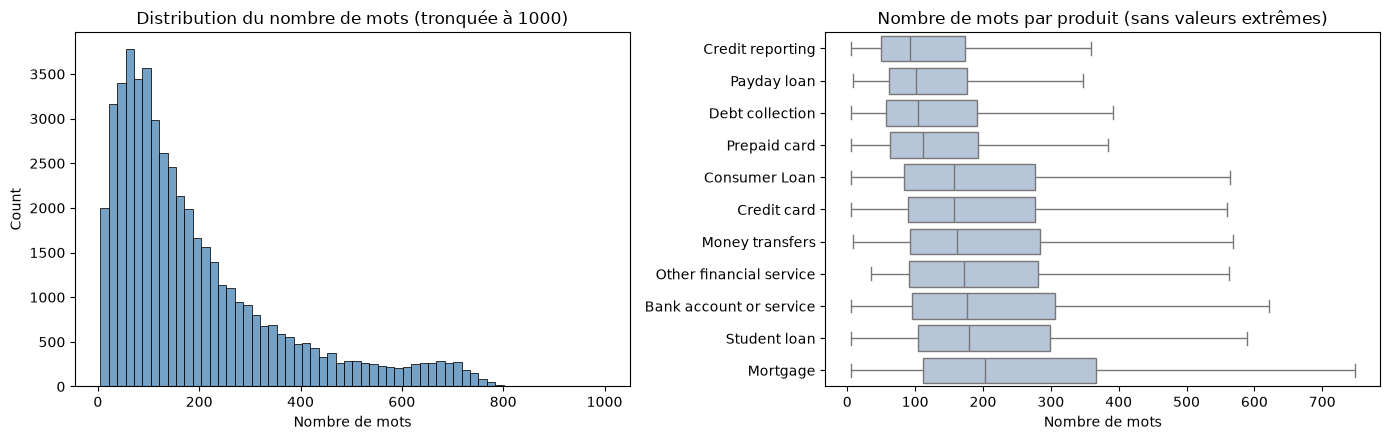

In [17]:
df["n_words"] = df["text"].str.split().str.len()
print(df["n_words"].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(df["n_words"].clip(upper=1000), bins=60, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution du nombre de mots (tronquée à 1000)")
axes[0].set_xlabel("Nombre de mots")
order = df.groupby("product")["n_words"].median().sort_values().index
sns.boxplot(data=df, y="product", x="n_words", order=order, showfliers=False, ax=axes[1], color="lightsteelblue")
axes[1].set_title("Nombre de mots par produit (sans valeurs extrêmes)")
axes[1].set_xlabel("Nombre de mots")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

In [18]:
n0 = len(df)
df = df.dropna(subset=["text", "product"])
df["text"] = df["text"].str.strip()
df = df[df["n_words"] >= 5]                         # textes trop courts : aucun contenu exploitable
df = df.drop_duplicates(subset="text", keep="first")  # évite la fuite train/test
print(f"{n0:,} → {len(df):,} réclamations ({n0 - len(df):,} supprimées)")

50,000 → 50,000 réclamations (0 supprimées)


In [19]:
PRODUCT_MAP = {
    "Debt collection": "Debt collection",
    "Credit reporting": "Credit reporting",
    "Mortgage": "Mortgage",
    "Credit card": "Card services",
    "Prepaid card": "Card services",
    "Bank account or service": "Bank account & transfers",
    "Money transfers": "Bank account & transfers",
    "Other financial service": "Bank account & transfers",
    "Consumer Loan": "Loans",
    "Student loan": "Loans",
    "Payday loan": "Loans",
    "Virtual currency": None,   # absente de cette version ; supprimée si présente (trop rare)
}

unknown = set(df["product"]) - set(PRODUCT_MAP)
print("Produits non prévus dans la table :", unknown or "aucun")

df["label"] = df["product"].map(PRODUCT_MAP)
print("Lignes supprimées (produit écarté ou inconnu) :", df["label"].isna().sum())
df = df.dropna(subset=["label"])

pd.crosstab(df["product"], df["label"])

Produits non prévus dans la table : aucun
Lignes supprimées (produit écarté ou inconnu) : 0


label,Bank account & transfers,Card services,Credit reporting,Debt collection,Loans,Mortgage
product,,,,,,
Bank account or service,4333,0,0,0,0,0
Consumer Loan,0,0,0,0,2807,0
Credit card,0,6034,0,0,0,0
Credit reporting,0,0,9029,0,0,0
Debt collection,0,0,0,13043,0,0
Money transfers,513,0,0,0,0,0
Mortgage,0,0,0,0,0,11361
Other financial service,78,0,0,0,0,0
Payday loan,0,0,0,0,558,0


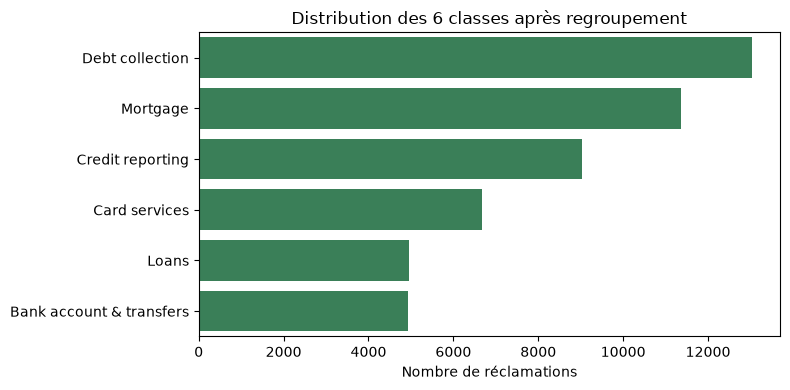

label
Debt collection             26.1 %
Mortgage                    22.7 %
Credit reporting            18.1 %
Card services               13.4 %
Loans                        9.9 %
Bank account & transfers     9.8 %
Name: count, dtype: str

Rapport classe majoritaire / minoritaire : 2.6x


In [20]:
label_counts = df["label"].value_counts()
plt.figure(figsize=(8, 4))
sns.barplot(x=label_counts.values, y=label_counts.index, color="seagreen")
plt.title("Distribution des 6 classes après regroupement")
plt.xlabel("Nombre de réclamations")
plt.ylabel("")
plt.tight_layout()
plt.show()
print((label_counts / label_counts.sum() * 100).round(1).astype(str) + " %")
print(f"\nRapport classe majoritaire / minoritaire : {label_counts.max() / label_counts.min():.1f}x")

In [ ]:
RANDOM_STATE = 42          # graine pour la reproductibilité
MAX_DOCS = 50_000
if len(df) > MAX_DOCS:
    df, _ = train_test_split(df, train_size=MAX_DOCS, stratify=df["label"], random_state=RANDOM_STATE)
df = df.reset_index(drop=True)
print("Taille du corpus de travail :", len(df))